# Adaptive GVAR: minimal experiment
The original GVAR forecasting equation is unchanged. A shared `Linear(3,8) → ReLU → Linear(8,1) → Sigmoid` scores additional directed edges. Features are signed zero-lag correlation and the two directional lag-1 correlations, computed once from the first calibration trials of the **training split**. Lag pairs never cross trial boundaries. Features use the same normalized log1p activity as forecasting.

Candidates are the nearest five eligible sources per target within 150 µm, excluding self-pairs and existing anatomical directions. Distance is not an MLP input. Sigmoid scores continuously weight this fixed candidate set; there is no extra pruning or edge-supervision loss.

Both graphs are row-normalized before mixing: $S_\theta=(1-\alpha)\bar A+\alpha\overline{\Delta A_\theta}$. Anatomical edges are retained. GVAR coefficients start from small nonzero random values, with **no ridge pre-fit**. Each minibatch jointly updates the MLP and GVAR coefficients using forecasting MSE plus coefficient regularization. The graph is rebuilt from the same fixed calibration features after parameter updates; it is never conditioned on a forecasting window. Evaluation uses a frozen graph. The best epoch is selected on validation; validation activity is never used for edge features.

The three models use identical coefficient initialization and Adam settings. 

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models/GVAR/gvar.py").exists())
sys.path.insert(0, str(ROOT / "models/GVAR"))
from data import load_data, load_graph, shift_operator, trials
from proximity_gvar import prepare_data, evaluate_trials
from gvar import GVAR
from adaptive_gvar import candidate_edges, correlation_features, AdaptiveGVAR

torch.set_num_threads(min(4, torch.get_num_threads()))
seed = 42
torch.manual_seed(seed)
P, K = 15, 3
alpha = 0.1
radius_um, neighbours = 150.0, 5
calibration_count = 20  # First training trials, fixed for the entire experiment.
epochs, lr, lam = 5, 1e-3, 1e-3
batch_size = 64

In [2]:
folder = prepare_data()  # Latest public CAVE, using the existing aligned cache.
data = load_data(str(folder))
positions = np.load(folder / "positions_um.npy")
edge_index, edge_weight = load_graph(str(folder), data["X"].shape[1])
A = shift_operator(edge_index, edge_weight, len(positions), kind="mean")
train_trials, val_trials = trials(data, "train"), trials(data, "val")
assert 1 <= calibration_count <= len(train_trials)

candidates = candidate_edges(positions, edge_index, neighbours, radius_um)
features = correlation_features(train_trials[:calibration_count], candidates)
print(json.loads((folder / "source.json").read_text()))
print(f"Calibration: first {calibration_count} of {len(train_trials)} training trials")
print(f"Anatomical edges: {A._nnz():,}; new candidates: {candidates.shape[1]:,}")
print(f"At most {neighbours} new sources per target; {len(val_trials)} validation trials")

Latest public CAVE materialization: v1926
{'datastack': 'minnie65_public', 'materialization': 1926, 'edge_source': 'cave_proofread', 'session': '4_7', 'positions': 'CAVE nucleus centres, micrometres', 'node_order': 'nucleus_ids.npy; shared by traces, positions and edge_index'}
Calibration: first 20 of 324 training trials
Anatomical edges: 947; new candidates: 5,293
At most 5 new sources per target; 71 validation trials


## Initialize, then train jointly
All models start with the **same** GVAR coefficient matrix sampled from Normal(0, 0.01). There is no ridge fit or frozen-coefficient stage. Anatomical and uniform models train only their GVAR coefficients; adaptive trains those coefficients and its shared MLP together. All use the same minibatch order, Adam settings and coefficient regularization.

The next cell only initializes models. **The following cell starts training**, with epoch and minibatch ETA. Every batch rebuilds its graph from fixed training-only features. Validation uses a frozen graph and selects the best epoch. History includes average gradient norms for the MLP and the k > 0 coefficients.


In [3]:
models = {}
for name, mix, learn in [("Anatomical", 0.0, False),
                         ("Uniform candidates", alpha, False),
                         ("Learned candidates", alpha, True)]:
    torch.manual_seed(seed)  # Identical initial h for all three models.
    models[name] = AdaptiveGVAR(A, candidates, features, P=P, K=K,
                               alpha=mix, learn_edges=learn)
vanilla, uniform, adaptive = models.values()
assert torch.equal(vanilla.h, adaptive.h) and torch.equal(uniform.h, adaptive.h)
print("Initialized only; no training has run.")
print(f"Initial graph-coefficient norm: {adaptive.h[1:].norm().item():.5f}")
print(f"Shared MLP parameters: {sum(p.numel() for p in adaptive.scorer.parameters())}")


Initialized only; no training has run.
Initial graph-coefficient norm: 0.06306
Shared MLP parameters: 41


In [4]:
# TRAINING STARTS HERE. Re-run the initialization cell first for a fresh experiment.
for name, model in models.items():
    print(f"\nTraining {name}")
    torch.manual_seed(seed)  # Same trial/window shuffle sequence for each model.
    model.fit(train_trials, val_trials, epochs=epochs, lr=lr, lam=lam,
              batch_size=batch_size)
    display(pd.DataFrame(model.history))



Training Anatomical


Joint GVAR: 100%|██████████| 5/5 [00:51<00:00, 10.38s/epoch, train_mse=0.54459, val_mse=0.43834]


,epoch,train_mse,val_mse,mlp_grad_norm,graph_h_grad_norm
0,0,NaN,0.803932,NaN,NaN
1,1,0.780772,0.546782,0.0,0.048035
2,2,0.628638,0.474358,0.0,0.038965
3,3,0.568741,0.445808,0.0,0.035501
4,4,0.549141,0.440165,0.0,0.032521
5,5,0.544589,0.438338,0.0,0.031970



Training Uniform candidates


Joint GVAR: 100%|██████████| 5/5 [01:14<00:00, 14.97s/epoch, train_mse=0.54431, val_mse=0.43804]


,epoch,train_mse,val_mse,mlp_grad_norm,graph_h_grad_norm
0,0,NaN,0.802929,NaN,NaN
1,1,0.779783,0.545974,0.0,0.046710
2,2,0.627928,0.473801,0.0,0.036993
3,3,0.568259,0.445413,0.0,0.033710
4,4,0.548805,0.439893,0.0,0.031049
5,5,0.544315,0.438035,0.0,0.030784



Training Learned candidates


Joint GVAR: 100%|██████████| 5/5 [03:21<00:00, 40.21s/epoch, train_mse=0.54427, val_mse=0.43801]


,epoch,train_mse,val_mse,mlp_grad_norm,graph_h_grad_norm
0,0,NaN,0.802929,NaN,NaN
1,1,0.779777,0.545967,0.000012,0.046737
2,2,0.627907,0.473780,0.000021,0.037108
3,3,0.568226,0.445389,0.000022,0.033998
4,4,0.548768,0.439862,0.000016,0.031476
5,5,0.544274,0.438005,0.000012,0.031241


,model,mse_without_graph,validation_mse,anatomical_edges,new_edges,total_edges
0,Anatomical,0.438615,0.438338,947,0,947
1,Uniform candidates,0.438632,0.438035,947,5293,6240
2,Learned candidates,0.438639,0.438005,947,5293,6240


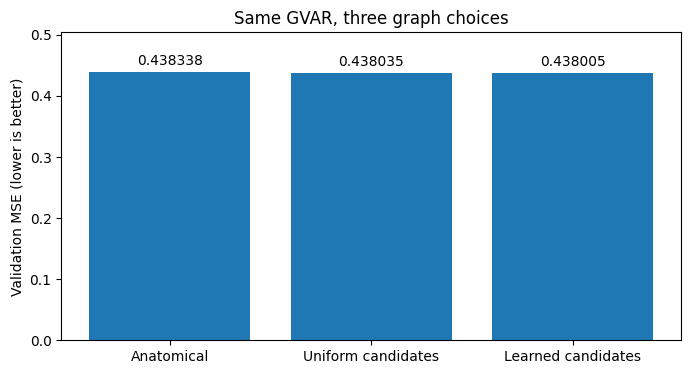

In [5]:
records = []
for name, model in models.items():
    score = evaluate_trials(model, val_trials, context=max(15, P), horizon=1, progress=False)
    # Ablate k > 0 without retraining: does the fitted model use its graph?
    self_only = GVAR(model.S, P=P, K=0)
    self_only.alpha = model.alpha
    with torch.no_grad():
        self_only.h.copy_(model.h[:1])
    ablated = evaluate_trials(self_only, val_trials, context=max(15, P), horizon=1, progress=False)
    records.append({"model": name, "mse_without_graph": ablated["gvar"]["mse"][0], "validation_mse": score["gvar"]["mse"][0],
                    "anatomical_edges": A._nnz(),
                    "new_edges": 0 if name == "Anatomical" else candidates.shape[1],
                    "total_edges": model.S._nnz()})
comparison = pd.DataFrame(records)
display(comparison)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(comparison.model, comparison.validation_mse)
ax.bar_label(bars, fmt="%.6f", padding=3)
ax.set(ylabel="Validation MSE (lower is better)", title="Same GVAR, three graph choices")
ax.margins(y=.15)
plt.show()

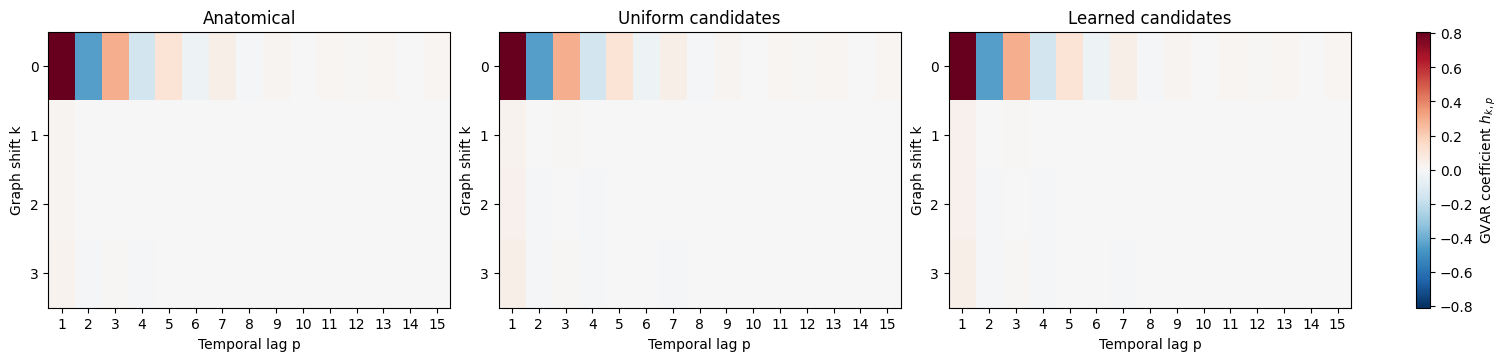

In [6]:
# Same color-matrix view as the original GVAR notebook: rows k, columns lag p.
limit = max(model.h.detach().abs().max().item() for model in models.values())
limit = max(limit, 1e-8)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), constrained_layout=True)
for ax, (name, model) in zip(axes, models.items()):
    h = model.h.detach().cpu().numpy()
    im = ax.imshow(h, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
    ax.set_xticks(range(P), range(1, P + 1))
    ax.set_yticks(range(K + 1))
    ax.set(title=name, xlabel="Temporal lag p", ylabel="Graph shift k")
    ax.grid(False)
fig.colorbar(im, ax=axes, label=r"GVAR coefficient $h_{k,p}$")
plt.show()


## Saving the models

In [8]:
# Save all three trained models currently in this kernel (no retraining).
checkpoint = ROOT / "models/GVAR/runs/adaptive_gvar.pt"
checkpoint.parent.mkdir(parents=True, exist_ok=True)
torch.save({"state_dict": adaptive.state_dict(),
            "P": P, "K": K, "alpha": alpha,
            "history": adaptive.history,
            "training": {"seed": seed, "epochs": epochs, "lr": lr,
                         "lam": lam, "batch_size": batch_size},
            "data_source": str(folder),
            "models": {name: {"state_dict": model.state_dict(),
                              "alpha": model.alpha,
                              "learn_edges": model.scorer is not None}
                       for name, model in models.items()}}, checkpoint)
print(f"Saved all three trained models to {checkpoint}")


Saved all three trained models to /mnt/c/Users/tymon/Delft/master/Neural-Forecasting/models/GVAR/runs/adaptive_gvar.pt


## Load models and produce the figures

In [9]:
# LOAD AND TEST ONLY: no fitting or optimizer steps.
# Re-run the save cell above to include all three already-trained models.
saved = torch.load(ROOT / "models/GVAR/runs/adaptive_gvar.pt",
                   map_location="cpu", weights_only=True)
test_data = load_data(saved["data_source"])
test_trials = trials(test_data, "test")
snapshots = saved.get("models", {"Learned candidates": {
    "state_dict": saved["state_dict"], "alpha": saved["alpha"], "learn_edges": True}})
if "models" not in saved:
    print("Older checkpoint: adaptive only. Re-run the save cell to include anatomical and uniform models.")

test_models = {}
for name, snapshot in snapshots.items():
    state = snapshot["state_dict"]
    model = AdaptiveGVAR(state["A"], state["candidates"], state["calibration_features"],
                         P=saved["P"], K=saved["K"], alpha=snapshot["alpha"],
                         learn_edges=snapshot["learn_edges"])
    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        model.update_graph()  # Rebuild S from the loaded MLP; S is not in state_dict.
    test_models[name + " (Adam)"] = model

# Saved anatomical ridge coefficients from the run that reproduced 0.4288.
ridge_path = ROOT / "models/GVAR/runs/proximity_20261010_234115/results.json"
ridge_run = json.loads(ridge_path.read_text())
assert ridge_run["source"] == json.loads((Path(saved["data_source"]) / "source.json").read_text())
ridge = GVAR(saved["state_dict"]["A"], P=ridge_run["config"]["P"], K=ridge_run["config"]["K"])
with torch.no_grad():
    ridge.h.copy_(torch.tensor(ridge_run["coefficients"]["0.0"]))
ridge.eval()
ridge.alpha = 0.0
test_models = {"Original anatomical GVAR (ridge)": ridge, **test_models}

# Match gvar_forecasting.ipynb: context=15, horizon=5, identical forecast origins.
test_scores = {}
for name, model in test_models.items():
    print(name)
    test_scores[name] = evaluate_trials(model, test_trials, context=15, horizon=5)
assert len({score["n_windows"] for score in test_scores.values()}) == 1
test_mse = pd.DataFrame({name: {"Test MSE h=1": score["gvar"]["mse"][0],
                               "Test MSE h=5": score["gvar"]["mse"][4]}
                         for name, score in test_scores.items()}).T
print(f"Same {next(iter(test_scores.values()))['n_windows']:,} held-out windows for every model")
display(test_mse.style.format("{:.6f}"))


/mnt/c/Users/tymon/Delft/master/Neural-Forecasting/venv/lib/python3.10/site-packages/torch/serialization.py:2244: UserWarning: Validating sparse tensor invariants because weights_only=True; this is an O(nnz) scan per sparse tensor and may be slow for large checkpoints.
  torch._utils._validate_loaded_sparse_tensors(weights_only=weights_only)


Original anatomical GVAR (ridge)


Evaluate alpha=0: 100%|██████████| 69/69 [00:05<00:00, 12.32trial/s]


Anatomical (Adam)


Evaluate alpha=0: 100%|██████████| 69/69 [00:05<00:00, 13.28trial/s]


Uniform candidates (Adam)


Evaluate alpha=0.1: 100%|██████████| 69/69 [00:07<00:00,  8.99trial/s]


Learned candidates (Adam)


Evaluate alpha=0.1: 100%|██████████| 69/69 [00:07<00:00,  9.39trial/s]


Same 4,434 held-out windows for every model


,Test MSE h=1,Test MSE h=5
Original anatomical GVAR (ridge),0.428761,0.733678
Anatomical (Adam),0.429021,0.734840
Uniform candidates (Adam),0.428679,0.734606
Learned candidates (Adam),0.428651,0.734581


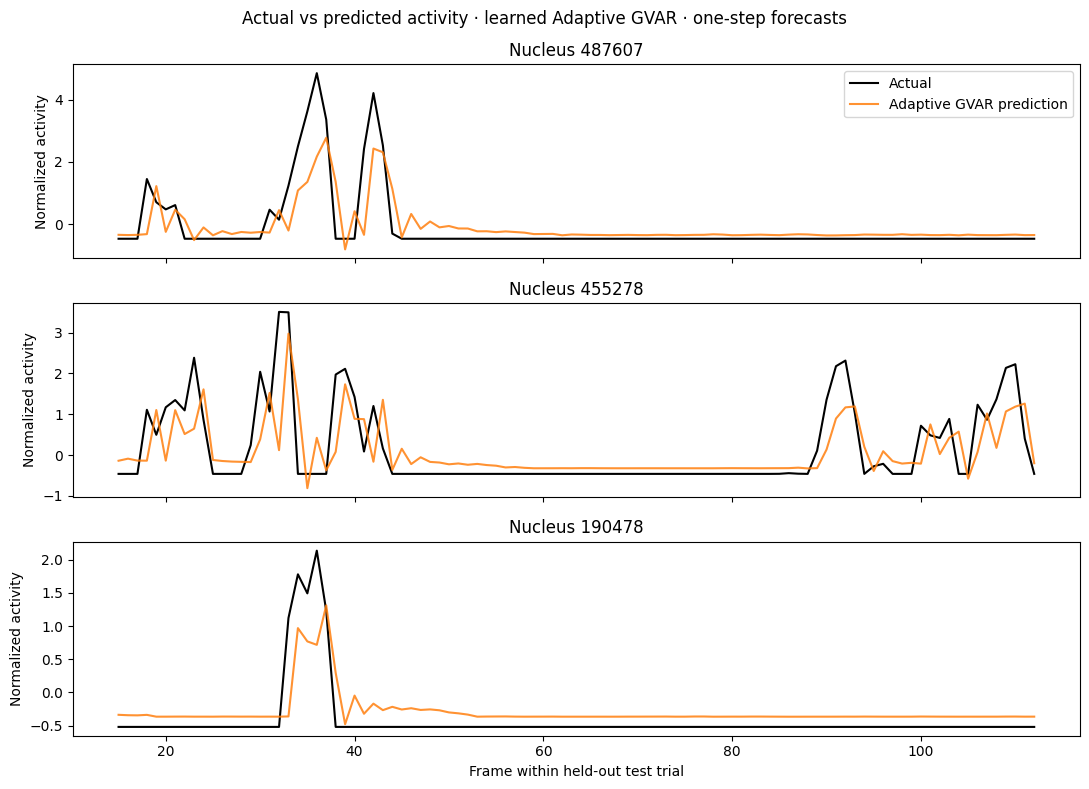

In [11]:
# Run after the loading/test cell. One-step forecasts use the true preceding P frames.
plot_model = test_models["Learned candidates (Adam)"]
context = max(15, plot_model.P)
example = next(x for x in test_trials if len(x) > context)
windows = example.unfold(0, context + 1, 1).permute(0, 2, 1)
with torch.no_grad():
    predicted = plot_model(windows[:, context - plot_model.P:context]).cpu().numpy()
actual = windows[:, -1].cpu().numpy()

plot_seed =   # Change this to sample another three neurons.
chosen = np.random.default_rng(plot_seed).choice(actual.shape[1], 3, replace=False)
node_ids = np.load(Path(saved["data_source"]) / "nucleus_ids.npy")
frames = np.arange(context, len(example))
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, neuron in zip(axes, chosen):
    ax.plot(frames, actual[:, neuron], color="black", label="Actual")
    ax.plot(frames, predicted[:, neuron], color="tab:orange", label="Adaptive GVAR prediction", alpha=.85)
    ax.set(ylabel="Normalized activity", title=f"Nucleus {node_ids[neuron]}")
axes[0].legend()
axes[-1].set_xlabel("Frame within held-out test trial")
fig.suptitle("Actual vs predicted activity · learned Adaptive GVAR · one-step forecasts")
fig.tight_layout()
plt.show()
